In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random
import time
import multiprocessing as mp
import seaborn as sns

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact
from tqdm import tqdm
import matplotlib.patches as mpatches
from scipy.cluster.hierarchy import linkage, fcluster

import sys
sys.path.append('../src')



/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
tumor ="t57"
infilename = f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt"
bincounts = pd.read_csv(infilename, sep="\t")

In [3]:
# Use ALL cells instead of filtered cells
all_cell_names = [col for col in bincounts.columns if col not in ['chrom', 'abstart', 'abend', 'lengths','loc.start','loc.end']]
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values


In [4]:
bincounts.head()

,chrom,loc.start,loc.end,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,...,TTTTGGAGTTTGCGTCT,TTTTGGATTCCTAGAGA,TTTTGGGAACAATAAGC,TTTTGGGGGTTTTCAGA,TTTTGGGTCTTTAGTCG,TTTTGGGTCTTTCTACT,TTTTGGTAAGCTCAAGT,TTTTGGTGCAGGAATCA,TTTTGGTGCAGGAGAAG,TTTTGGTTTGGAAGTAC
0,chr1,0,45387037,0,45387037,570,1604,403,1325,853,...,214,1224,790,399,1536,1146,1064,961,16,834
1,chr1,45972336,119478274,45972336,119478274,928,5401,596,4437,2675,...,1421,2223,1209,593,4682,1092,671,3250,882,1429
2,chr1,120035598,175362842,120035598,175362842,506,2172,294,1671,1987,...,299,785,542,2015,1815,705,388,1264,2146,669
3,chr1,175900450,182029442,175900450,182029442,83,230,66,184,232,...,12,142,72,230,181,74,63,76,250,132
4,chr1,182578512,248389233,182578512,248389233,819,2760,612,1954,1335,...,152,1066,855,600,2012,1097,309,768,916,1228


In [5]:
bincounts["length"] = bincounts["abend"] - bincounts["abstart"]
L = bincounts["length"].values
L = (L / L.sum())*len(L)  # Normalize lengths to sum to the number of bins

In [6]:
data = bincounts[cells]

In [7]:
norm_data = (data/data.sum())*len(data)  # Normalize counts to sum to the number of bins

In [8]:
c1 = cells[0]
c2 = cells[1]

In [9]:
def pairwise_distance(pair):
    # Compute the pairwise distance between two cells

    c1, c2 = pair
    p1 = norm_data[c1].values
    p2 = norm_data[c2].values
    return c1, c2, np.sum(L*((p1 - p2)**2))

In [10]:
t1 = time.time()
print(pairwise_distance((c1, c2)))
t2 = time.time()

('AAAACCAACCTGATAAC', 'AAAACCAACTTTTGACG', 27.5373158270157)


In [11]:
t2-t1

0.0019812583923339844

In [12]:
# Compute pairwise distances for all cells  
num_processes = mp.cpu_count() - 1  # Leave one CPU free
cell_pairs = list(itertools.combinations(cells, 2))
with mp.Pool(processes=num_processes) as pool:
    results = list(tqdm(pool.imap(pairwise_distance, cell_pairs), total=len(cell_pairs)))

100%|██████████| 2951235/2951235 [04:35<00:00, 10694.83it/s]


In [13]:
results_df = pd.DataFrame(results, columns=['cell1', 'cell2', 'distance'])

In [14]:
results_df.head()

,cell1,cell2,distance
0,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,27.537316
1,AAAACCAACCTGATAAC,AAAACCAATTTCAGTAC,1.810621
2,AAAACCAACCTGATAAC,AAAACCACTGGCCTTAC,29.288279
3,AAAACCAACCTGATAAC,AAAACCAGCTTAGATAC,27.692403
4,AAAACCAACCTGATAAC,AAAACCAGTGAGTCTAC,2.754412


<AxesSubplot:>

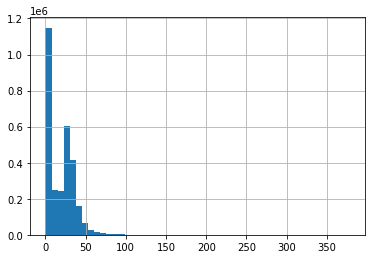

In [15]:
results_df["distance"].hist(bins  = 50)

In [16]:
results_df["distance"].describe()

count    2.951235e+06
mean     1.872263e+01
std      1.681776e+01
min      1.484057e-01
25%      2.609865e+00
50%      1.848086e+01
75%      3.005357e+01
max      3.784371e+02
Name: distance, dtype: float64

In [17]:
distance_matrix = np.zeros((len(cells), len(cells)))
cell_index = {cell: idx for idx, cell in enumerate(cells)}
results_df["idx1"] = results_df["cell1"].map(cell_index)
results_df["idx2"] = results_df["cell2"].map(cell_index)
count = 0
for dist, idx1, idx2  in results_df[["distance", "idx1", "idx2"]].values:
    distance_matrix[int(idx1), int(idx2)] = min(dist, 100)  #cap distances at 100 to avoid outliers
    distance_matrix[int(idx2), int(idx1)] = min(dist, 100)  # Symmetric
    # distance_matrix[int(idx1), int(idx2)] = dist
    # distance_matrix[int(idx2), int(idx1)] = dist  # Symmetric
    if count % 10000 == 0:
        print(f"Processed {count} pairs")
    count += 1



Processed 0 pairs
Processed 10000 pairs
Processed 20000 pairs
Processed 30000 pairs
Processed 40000 pairs
Processed 50000 pairs
Processed 60000 pairs
Processed 70000 pairs
Processed 80000 pairs
Processed 90000 pairs
Processed 100000 pairs
Processed 110000 pairs
Processed 120000 pairs
Processed 130000 pairs
Processed 140000 pairs
Processed 150000 pairs
Processed 160000 pairs
Processed 170000 pairs
Processed 180000 pairs
Processed 190000 pairs
Processed 200000 pairs
Processed 210000 pairs
Processed 220000 pairs
Processed 230000 pairs
Processed 240000 pairs
Processed 250000 pairs
Processed 260000 pairs
Processed 270000 pairs
Processed 280000 pairs
Processed 290000 pairs
Processed 300000 pairs
Processed 310000 pairs
Processed 320000 pairs
Processed 330000 pairs
Processed 340000 pairs
Processed 350000 pairs
Processed 360000 pairs
Processed 370000 pairs
Processed 380000 pairs
Processed 390000 pairs
Processed 400000 pairs
Processed 410000 pairs
Processed 420000 pairs
Processed 430000 pairs
Pr

In [79]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")

In [80]:
A_df.head()

,cell,population,normal_population
0,AAAACCAACCTGATAAC,C11,True
1,AAAACCAATTTCAGTAC,C11,True
2,AAAACCAGTGAGTCTAC,C11,True
3,AAAACCATGAGGAGAAG,C11,True
4,AAAACCGAACCCGTACA,C11,True


In [81]:
normal_pop = A_df[A_df["normal_population"] == True]["population"].values[0]
all_cell_type_map = dict(zip(A_df["cell"], A_df["population"]))

# 2. Create a pandas Series for the row colors, ensuring the order matches `ordered_cell_ids`
row_colors_list_full = [all_cell_type_map.get(cell) for cell in cells]
row_colors_series_full = pd.Series(row_colors_list_full, index=cells, name='Cell Type')

#define a color palette for the populations
Unique_populations = A_df["population"].unique()
# Create a color palette with a unique color for each population
palette = sns.color_palette("hsv", len(Unique_populations))
# Create a dictionary mapping populations to colors
population_color_map = dict(zip(Unique_populations, palette))
population_color_map[normal_pop] = (0.5, 0.5, 0.5)  # Set normal population to gray

mapped_colors_full = row_colors_series_full.map(population_color_map)




/home/ranade/miniconda3/lib/python3.6/site-packages/seaborn/matrix.py:603: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  metric=self.metric)


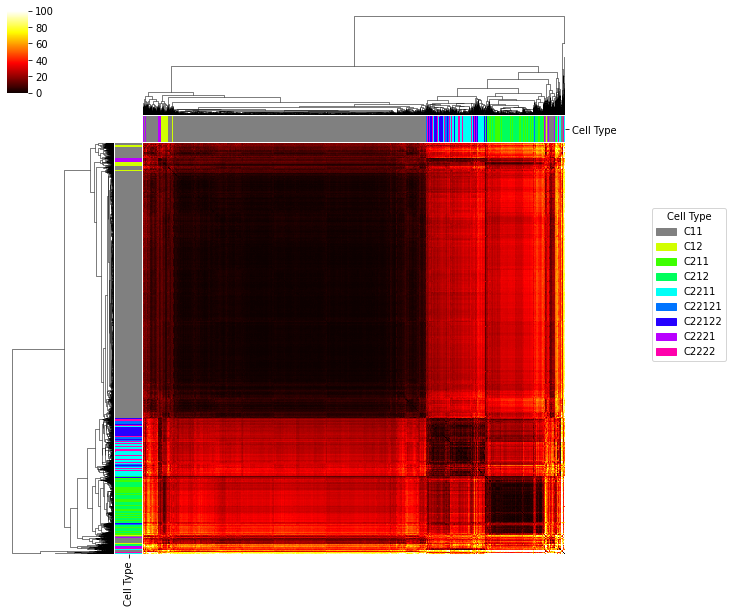

In [82]:
g = sns.clustermap(pd.DataFrame(distance_matrix, index=cells, columns=cells),
                   row_cluster=True, 
                   col_cluster=True,
                   row_colors=mapped_colors_full,
                   col_colors=mapped_colors_full,
                   cmap='hot',
                   xticklabels=False,
                   yticklabels=False)

# Create legend patches for each cell type
legend_patches = [mpatches.Patch(color=color, label=cell_type) 
                  for cell_type, color in population_color_map.items()]
# Add the legend to the figure
g.fig.legend(handles=legend_patches,
             title='Cell Type',
             loc='center left',
             bbox_to_anchor=(1.02, 0.5),
             borderaxespad=0.)

In [83]:
row_linkage = g.dendrogram_row.linkage
row_clusters = fcluster(row_linkage, t=5, criterion="maxclust")

In [84]:
Counter(row_clusters)

Counter({1: 1630, 2: 780, 3: 12, 4: 6, 5: 2})

In [85]:
def find_main_clusters(row_linkage, min_size=25, min_clusters=5):
    """
    Find the number of clusters such that at least `min_clusters` clusters have at least `min_size` members.
    
    Parameters:
    - row_linkage: The linkage matrix from hierarchical clustering.
    - min_size: Minimum size of clusters to be considered "large".
    - min_clusters: Minimum number of large clusters required.
    
    Returns:
    - labels: Cluster labels for each observation.
    - k: The number of clusters found.
    """
    for k in range(min_clusters, 100):
        labels = fcluster(row_linkage, t=k, criterion="maxclust")
        sizes = pd.Series(labels).value_counts()
        large_clusters = (sizes >= min_size).sum()
        if large_clusters >= min_clusters:
            return labels, k
    return None, None  # If no suitable k is found



In [86]:
len(A_df["population"].unique())

9

In [87]:
labels, k = find_main_clusters(row_linkage, min_size=100, min_clusters=3)

In [88]:
from visualization import plot_overlap_matrix_figure

In [89]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

C11
C12
C211
C212
C2211
C22121
C22122
C2221
C2222


In [90]:
label_dict = dict(zip(cells, labels))

In [91]:
A_df["heirarchical_cluster"] = A_df["cell"].map(label_dict)

In [95]:
A_dict = {}
H_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }
exclude_counter = 0
for cluster in A_df['heirarchical_cluster'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['heirarchical_cluster'] == cluster]['cell'].tolist()
    if len(cells_in_cluster) < 100:
        exclude_counter += len(cells_in_cluster)
        continue
    H_dict[cluster] = {
        'cells': cells_in_cluster
    }

C11
C12
C211
C212
C2211
C22121
C22122
C2221
C2222
1
5
4
12
13
11
3
19
14
8
16
6
2
9
7
17
18
10
15


In [96]:
exclude_counter

113


Overlap Matrix (A rows vs B cols):
Pop          C11     C12    C211    C212   C2211  C22121  C22122   C2221   C2222
1           1557      46       0       0       0       0       0      27       0
2              0       0       1       2     143      25      92       6      74
3              0       1     128     197       0       9       4       3       2


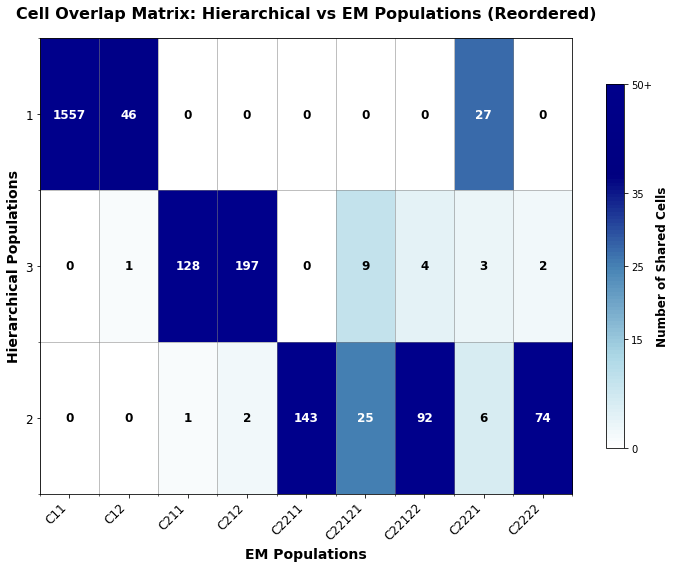

In [97]:
overlap_df = plot_overlap_matrix_figure(H_dict, A_dict, name1="Hierarchical", name2="EM")

In [100]:
sub_df = A_df[A_df["heirarchical_cluster"].isin(H_dict.keys())]

In [103]:
normal_pop = sub_df[sub_df["normal_population"] == True]["heirarchical_cluster"].values[0]
all_cell_type_map = dict(zip(A_df["cell"], A_df["heirarchical_cluster"]))

# 2. Create a pandas Series for the row colors, ensuring the order matches `ordered_cell_ids`
row_colors_list_full = [all_cell_type_map.get(cell) for cell in cells]
row_colors_series_full = pd.Series(row_colors_list_full, index=cells, name='Cell Type')

#define a color palette for the populations
Unique_populations = sub_df["heirarchical_cluster"].unique()
# Create a color palette with a unique color for each population
palette = sns.color_palette("hsv", len(Unique_populations))
# Create a dictionary mapping populations to colors
population_color_map = dict(zip(Unique_populations, palette))
population_color_map[normal_pop] = (0.5, 0.5, 0.5)  # Set normal population to gray

mapped_colors_full = row_colors_series_full.map(population_color_map)



/home/ranade/miniconda3/lib/python3.6/site-packages/seaborn/matrix.py:603: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  metric=self.metric)


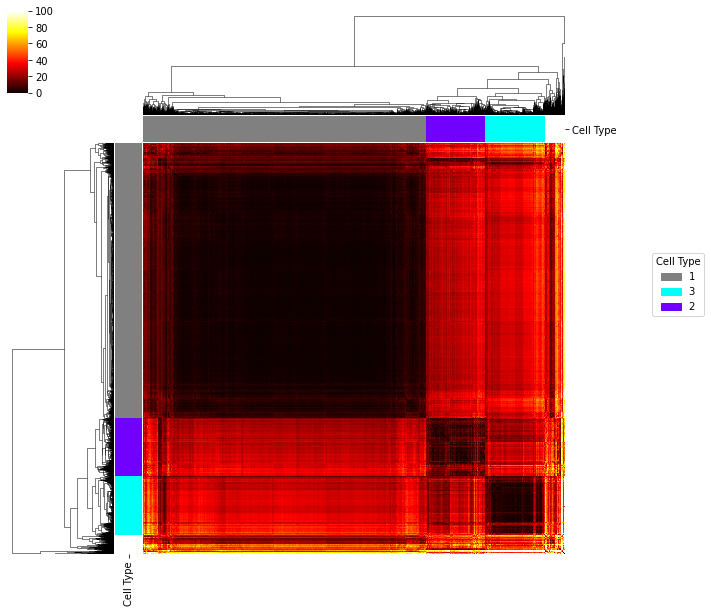

In [104]:
g = sns.clustermap(pd.DataFrame(distance_matrix, index=cells, columns=cells),
                   row_cluster=True, 
                   col_cluster=True,
                   row_colors=mapped_colors_full,
                   col_colors=mapped_colors_full,
                   cmap='hot',
                   xticklabels=False,
                   yticklabels=False)

# Create legend patches for each cell type
legend_patches = [mpatches.Patch(color=color, label=cell_type) 
                  for cell_type, color in population_color_map.items()]
# Add the legend to the figure
g.fig.legend(handles=legend_patches,
             title='Cell Type',
             loc='center left',
             bbox_to_anchor=(1.02, 0.5),
             borderaxespad=0.)